# Logistic Regression Classification

This notebook uses the cleaned credit card default dataset to evaluate a Logistic Regression classifier. It is separated from the data-cleaning notebook so the model can be run and reviewed independently.


## 1. Import Libraries, Load Cleaned Data, and Prepare Train/Test Sets


In [ ]:
from google.colab import files

# Upload the cleaned dataset.
uploaded = files.upload()

# Load the cleaned dataset.
df = pd.read_csv("cleaned_credit_card_data.csv")

print("Dataset loaded successfully.")
print("Number of Observations:", df.shape[0])
print("Number of Variables:", df.shape[1])

Saving cleaned_credit_card_data.csv to cleaned_credit_card_data.csv
Dataset loaded successfully.
Number of Observations: 30000
Number of Variables: 24


In [ ]:
# Import libraries.
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    roc_curve
)

# Load the cleaned dataset exported from the EDA notebook.
df = pd.read_csv("cleaned_credit_card_data.csv")

# Separate predictors and target variable.
X = df.drop(columns=["DEFAULT"])
y = df["DEFAULT"]

# Create the same 80/20 stratified split used in the combined notebook.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

categorical_features = [
    "SEX",
    "EDUCATION",
    "MARRIAGE"
]

numeric_features = [
    column for column in X.columns
    if column not in categorical_features
]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "numeric",
            StandardScaler(),
            numeric_features
        )
    ]
)

print(f"Training Observations: {X_train.shape[0]:,}")
print(f"Testing Observations: {X_test.shape[0]:,}")
print(f"Training Default Rate: {y_train.mean() * 100:.2f}%")
print(f"Testing Default Rate: {y_test.mean() * 100:.2f}%")


Training Observations: 24,000
Testing Observations: 6,000
Training Default Rate: 22.12%
Testing Default Rate: 22.12%


## 2. Baseline Classification


In [ ]:
# Create a baseline classifier for comparison.
baseline_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", DummyClassifier(strategy="most_frequent"))
    ]
)

baseline_model.fit(X_train, y_train)

baseline_predictions = baseline_model.predict(X_test)
baseline_probabilities = baseline_model.predict_proba(X_test)[:, 1]

baseline_accuracy = accuracy_score(y_test, baseline_predictions)
baseline_precision = precision_score(
    y_test, baseline_predictions, zero_division=0
)
baseline_recall = recall_score(
    y_test, baseline_predictions, zero_division=0
)
baseline_f1 = f1_score(
    y_test, baseline_predictions, zero_division=0
)
baseline_auc = roc_auc_score(y_test, baseline_probabilities)

print(f"Baseline Accuracy: {baseline_accuracy:.4f}")
print(f"Baseline Precision: {baseline_precision:.4f}")
print(f"Baseline Recall: {baseline_recall:.4f}")
print(f"Baseline F1 Score: {baseline_f1:.4f}")
print(f"Baseline ROC-AUC: {baseline_auc:.4f}")


Baseline Accuracy: 0.7788
Baseline Precision: 0.0000
Baseline Recall: 0.0000
Baseline F1 Score: 0.0000
Baseline ROC-AUC: 0.5000


## 3. Logistic Regression


In [ ]:
from sklearn.linear_model import LogisticRegression

# Create and train the logistic regression model.
logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            LogisticRegression(
                max_iter=2000,
                class_weight="balanced",
                random_state=42
            )
        )
    ]
)

logistic_model.fit(X_train, y_train)

logistic_predictions = logistic_model.predict(X_test)
logistic_probabilities = logistic_model.predict_proba(X_test)[:, 1]

logistic_accuracy = accuracy_score(y_test, logistic_predictions)
logistic_precision = precision_score(
    y_test, logistic_predictions, zero_division=0
)
logistic_recall = recall_score(
    y_test, logistic_predictions, zero_division=0
)
logistic_f1 = f1_score(
    y_test, logistic_predictions, zero_division=0
)
logistic_auc = roc_auc_score(y_test, logistic_probabilities)

print(f"Logistic Regression Accuracy: {logistic_accuracy:.4f}")
print(f"Logistic Regression Precision: {logistic_precision:.4f}")
print(f"Logistic Regression Recall: {logistic_recall:.4f}")
print(f"Logistic Regression F1 Score: {logistic_f1:.4f}")
print(f"Logistic Regression ROC-AUC: {logistic_auc:.4f}")

print("\nLogistic Regression Confusion Matrix:")
print(confusion_matrix(y_test, logistic_predictions))


Logistic Regression Accuracy: 0.6782
Logistic Regression Precision: 0.3677
Logistic Regression Recall: 0.6323
Logistic Regression F1 Score: 0.4649
Logistic Regression ROC-AUC: 0.7106

Logistic Regression Confusion Matrix:
[[3230 1443]
 [ 488  839]]


### Logistic Regression Interpretation

Using the saved results from the original combined notebook, Logistic Regression achieved an accuracy of **67.82%**, precision of **36.77%**, recall of **63.23%**, F1 score of **46.49%**, and ROC-AUC of **0.7106**. Its lower accuracy reflects the class-balanced setup, while its higher recall means it identified a larger share of customers who actually defaulted.


## 4. Model Comparison


In [ ]:
model_comparison = pd.DataFrame({
    "Model": ["Baseline", "Logistic Regression"],
    "Accuracy": [baseline_accuracy, logistic_accuracy],
    "Precision": [baseline_precision, logistic_precision],
    "Recall": [baseline_recall, logistic_recall],
    "F1 Score": [baseline_f1, logistic_f1],
    "ROC-AUC": [baseline_auc, logistic_auc]
})

model_comparison[
    ["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"]
] = model_comparison[
    ["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"]
].round(4)

model_comparison


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Baseline,0.7788,0.0000,0.0000,0.0000,0.5000
1,Logistic Regression,0.6782,0.3677,0.6323,0.4649,0.7106


## 5. Confusion Matrix and ROC Curve


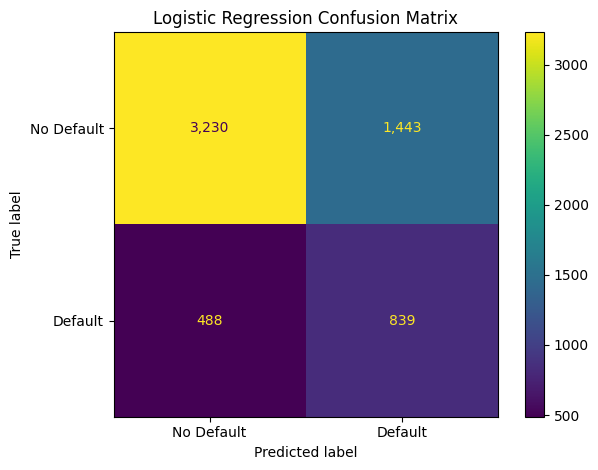

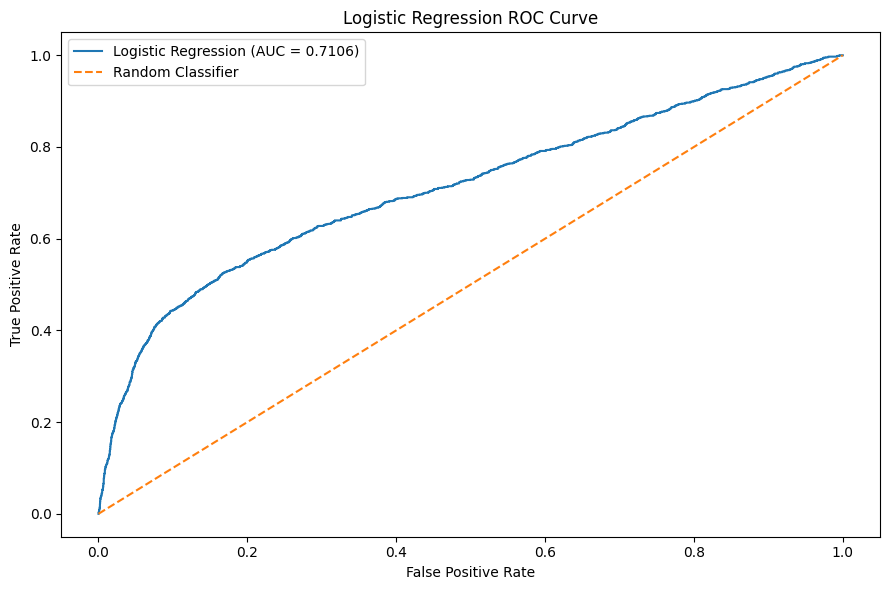

In [ ]:
display = ConfusionMatrixDisplay(
    confusion_matrix=confusion_matrix(y_test, logistic_predictions),
    display_labels=["No Default", "Default"]
)
display.plot(values_format=",")
plt.title("Logistic Regression Confusion Matrix")
plt.tight_layout()
plt.show()

false_positive_rate, true_positive_rate, thresholds = roc_curve(
    y_test, logistic_probabilities
)

plt.figure(figsize=(9, 6))
plt.plot(
    false_positive_rate,
    true_positive_rate,
    label=f"Logistic Regression (AUC = {logistic_auc:.4f})"
)
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")
plt.title("Logistic Regression ROC Curve")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.tight_layout()
plt.show()
